# Elastic Deformation of Two-Dimensional Objects
**Group 02 · Numerical Linear Algebra and PDEs · companion notebook to `Group02_Report.pdf`**

This notebook reproduces every number, table and figure in the report from scratch. It runs top to bottom with no other files.

**What it does**
1. Builds the linear system $A\mathbf{x}=\mathbf{b}$ for a thin elastic plate using linear triangular finite elements (report §1–2).
2. Solves a small system by hand-checkable direct methods (report §4).
3. Compares direct and iterative solvers on a larger system under one shared protocol (report §3–4).
4. Studies how conditioning and solver effort change with mesh refinement (report §4).
5. Validates the solution with equilibrium checks and an exact test case (report §4).
6. Runs the experiments on additional objects: a long rectangle and a square with a hole (report §5–6).

**Units** throughout: metres, newtons, pascals.

**Run time:** a few minutes on a laptop. Most of it is Gauss–Seidel and the iteration-capped methods in Part 3.

## 0. Setup and dependencies

Required: `numpy`, `scipy`, `matplotlib` (standard scientific Python), and `triangle` (a Python interface to J. R. Shewchuk's Triangle mesh generator, used only in Part 6). The next cell installs `triangle` if it is missing.

In [1]:
import importlib.util, subprocess, sys
if importlib.util.find_spec("triangle") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", "triangle"])

import json, platform
from time import perf_counter

import numpy as np
import scipy
import matplotlib
import matplotlib.pyplot as plt
import triangle as tr
from scipy.linalg import cho_factor, cho_solve, eigvalsh, inv, lu_factor, lu_solve
from scipy.sparse import coo_matrix, csr_matrix, diags, tril
from scipy.sparse.linalg import cg, eigsh, gmres, minres, splu, spsolve_triangular

np.set_printoptions(precision=4, suppress=False, linewidth=110)
print("python", platform.python_version(), "| numpy", np.__version__, "| scipy", scipy.__version__,
      "| matplotlib", matplotlib.__version__, "| triangle", getattr(tr, "__version__", "installed"))
print(platform.platform())

python 3.12.2 | numpy 1.26.4 | scipy 1.13.1 | matplotlib 3.9.2 | triangle 20250106
macOS-14.8.9-arm64-arm-64bit


## 1. Physical model (report §1–2)

A thin steel plate of thickness $t$ lies in the $xy$-plane. Its left edge is clamped and a uniform traction $p$ pulls its right edge. We want the displacement field $\mathbf{u}(x,y) = (u_x, u_y)$.

The chain of ideas:

| Quantity | Meaning | Relation |
|---|---|---|
| displacement $\mathbf{u}$ | how far each point moves | unknown |
| strain $\boldsymbol\varepsilon = (\varepsilon_{xx}, \varepsilon_{yy}, \gamma_{xy})$ | local stretching and shearing | derivatives of $\mathbf{u}$ |
| stress $\boldsymbol\sigma = (\sigma_{xx}, \sigma_{yy}, \tau_{xy})$ | internal force per area | $\boldsymbol\sigma = D\,\boldsymbol\varepsilon$ (Hooke's law) |
| equilibrium | every piece is in force balance | gives $K\mathbf{d} = \mathbf{f} + \mathbf{r}$ |

**Plane stress** (the plate is thin, so stresses through the thickness vanish) gives the material matrix

$$
D = \frac{E}{1-\nu^2}\begin{pmatrix}1 & \nu & 0\\ \nu & 1 & 0\\ 0 & 0 & \tfrac{1-\nu}{2}\end{pmatrix},
$$

with Young's modulus $E$ (stiffness) and Poisson's ratio $\nu$ (sideways contraction). $D$ is symmetric positive definite whenever $E>0$ and $-1<\nu<1/2$.

**Baseline case** (used in Parts 2–5): $1\times1$ m steel plate, $E = 200$ GPa, $\nu = 0.3$, $t = 1$ cm, $p = 100$ MPa, so the total pull is $p\,t\,(1\text{ m}) = 10^6$ N.

In [2]:
E, NU, T, P = 200e9, 0.3, 0.01, 100e6     # Pa, -, m, Pa

def material_matrix(E, nu):
    # Plane-stress constitutive matrix D in sigma = D eps (engineering shear strain).
    if not (E > 0 and -1 < nu < 0.5):
        raise ValueError("need E > 0 and -1 < nu < 0.5 for a positive definite D")
    return E / (1 - nu**2) * np.array([[1, nu, 0], [nu, 1, 0], [0, 0, (1 - nu) / 2]])

D = material_matrix(E, NU)
print("D [GPa] =\n", D / 1e9)
print("eigenvalues of D [GPa]:", np.linalg.eigvalsh(D) / 1e9, "-> all positive, D is SPD")

D [GPa] =
 [[219.7802  65.9341   0.    ]
 [ 65.9341 219.7802   0.    ]
 [  0.       0.      76.9231]]
eigenvalues of D [GPa]: [ 76.9231 153.8462 285.7143] -> all positive, D is SPD


## 2. From triangles to the stiffness matrix (report §2)

We cut the plate into triangles and track only the corner (node) displacements. Node $i$ has two unknowns $(u_{x,i}, u_{y,i})$. We order them as $\mathbf{d} = [u_{x,0}, u_{y,0}, u_{x,1}, u_{y,1}, \dots]$.

Inside one triangle the displacement varies **linearly** between its three corners, so the strain is constant there: $\boldsymbol\varepsilon = B\,\mathbf{d}_e$, where $\mathbf{d}_e$ holds the triangle's 6 corner displacements. For corners $(x_k, y_k)$ in counter-clockwise order, with $b_i = y_j - y_k$, $c_i = x_k - x_j$ ($i,j,k$ cyclic) and area $\Delta$:

$$
B = \frac{1}{2\Delta}\begin{pmatrix} b_1 & 0 & b_2 & 0 & b_3 & 0\\ 0 & c_1 & 0 & c_2 & 0 & c_3\\ c_1 & b_1 & c_2 & b_2 & c_3 & b_3\end{pmatrix},
\qquad
K_e = t\,\Delta\, B^\top D B \quad (6\times 6).
$$

The global stiffness matrix $K$ is the sum of all $K_e$, each placed in the rows and columns of its triangle's unknowns (**assembly**). Nodes shared by several triangles collect contributions from each.

In [3]:
def strain_displacement(xy):
    # Return (B, area) for one triangle with CCW corner coordinates xy (3, 2).
    (x1, y1), (x2, y2), (x3, y3) = xy
    two_area = (x2 - x1) * (y3 - y1) - (x3 - x1) * (y2 - y1)
    if two_area <= 0:
        raise ValueError("triangle is degenerate or not counter-clockwise")
    b = np.array([y2 - y3, y3 - y1, y1 - y2])
    c = np.array([x3 - x2, x1 - x3, x2 - x1])
    B = np.zeros((3, 6))
    B[0, 0::2] = b          # eps_xx   = du_x/dx
    B[1, 1::2] = c          # eps_yy   = du_y/dy
    B[2, 0::2] = c          # gamma_xy = du_x/dy + du_y/dx
    B[2, 1::2] = b
    return B / two_area, two_area / 2


def element_stiffness(xy, D, t):
    B, area = strain_displacement(xy)
    return t * area * B.T @ D @ B


def assemble(nodes, triangles, E, nu, t):
    # Global stiffness K (sparse CSR, 2N x 2N). Duplicate entries from shared nodes are summed.
    D = material_matrix(E, nu)
    rows, cols, vals = [], [], []
    for tri in triangles:
        Ke = element_stiffness(nodes[tri], D, t)
        dofs = np.column_stack([2 * tri, 2 * tri + 1]).ravel()
        rows.append(np.repeat(dofs, 6)); cols.append(np.tile(dofs, 6)); vals.append(Ke.ravel())
    n = 2 * len(nodes)
    K = coo_matrix((np.concatenate(vals), (np.concatenate(rows), np.concatenate(cols))), shape=(n, n)).tocsr()
    K.sum_duplicates()
    return K

**Quick check on one triangle.** $K_e$ must be symmetric. It must also have exactly three zero eigenvalues: two rigid translations and one rigid rotation move the triangle without straining it, so they store no energy.

In [4]:
xy = np.array([[0.0, 0.0], [1.0, 0.0], [0.0, 1.0]])
Ke = element_stiffness(xy, D, T)
ev = np.linalg.eigvalsh(Ke)
print("symmetric:", np.allclose(Ke, Ke.T))
print("eigenvalues of K_e / max:", np.round(ev / ev.max(), 12))

symmetric: True
eigenvalues of K_e / max: [-0.      0.      0.      0.2792  0.4477  1.    ]


### Loads, supports and the reduced system

* **Loads.** A constant line load $\mathbf{q}$ (N/m) on a boundary edge of length $\ell$ gives each of its two end nodes the force $\mathbf{q}\,\ell/2$. For a traction $p$ on a plate of thickness $t$, $\mathbf{q} = (t\,p, 0)$.
* **Supports.** Clamped nodes have prescribed displacement $0$. Split the unknowns into free ($F$) and constrained ($C$):

$$
\begin{pmatrix}K_{FF} & K_{FC}\\ K_{CF} & K_{CC}\end{pmatrix}\begin{pmatrix}\mathbf{d}_F\\ \mathbf{d}_C\end{pmatrix} = \begin{pmatrix}\mathbf{f}_F\\ \mathbf{f}_C + \mathbf{r}_C\end{pmatrix}
\quad\Longrightarrow\quad
\underbrace{K_{FF}}_{A}\,\underbrace{\mathbf{d}_F}_{\mathbf{x}} = \underbrace{\mathbf{f}_F - K_{FC}\,\mathbf{d}_C}_{\mathbf{b}}.
$$

The support reactions $\mathbf{r}_C$ follow afterwards from the second block row.

**Why $A$ is SPD.** The stored energy is $\tfrac12\mathbf{d}^\top K\mathbf{d}\ge0$. On its own, $K$ is singular: rigid motions store no energy. Clamping removes every rigid motion, so $\mathbf{x}^\top A\mathbf{x}>0$ for every $\mathbf{x}\neq0$.

In [5]:
def constant_edge_load(nodes, edges, q):
    # Nodal forces (length 2N) for a constant line load q = (qx, qy) [N/m] on the given edges.
    edges = np.asarray(edges)
    lengths = np.linalg.norm(nodes[edges[:, 1]] - nodes[edges[:, 0]], axis=1)
    forces = np.zeros_like(nodes)
    for end in (0, 1):
        np.add.at(forces, edges[:, end], lengths[:, None] * np.asarray(q, float) / 2)
    return forces.ravel()


def reduce_system(K, f, constrained, values):
    # Return A, b, free, d; afterwards fill d[free] with the solution of A x = b.
    c = np.asarray(constrained, dtype=int)
    free = np.setdiff1d(np.arange(f.size), c)
    d = np.zeros(f.size); d[c] = values
    return K[free][:, free], f[free] - K[free][:, c] @ values, free, d


def xy_dofs(node_ids):
    node_ids = np.asarray(node_ids)
    return np.column_stack([2 * node_ids, 2 * node_ids + 1]).ravel()

### Structured mesh of a rectangle

Parts 2–5 use a regular grid: $n_x\times n_y$ square cells, each cut into two triangles along the bottom-left to top-right diagonal. This gives $(n_x+1)(n_y+1)$ nodes.

In [6]:
def rectangle_mesh(Lx, Ly, nx, ny):
    xs, ys = np.linspace(0, Lx, nx + 1), np.linspace(0, Ly, ny + 1)
    X, Y = np.meshgrid(xs, ys)
    nodes = np.column_stack([X.ravel(), Y.ravel()])
    idx = lambda i, j: i + j * (nx + 1)
    tris = []
    for j in range(ny):
        for i in range(nx):
            n0, n1, n2, n3 = idx(i, j), idx(i + 1, j), idx(i + 1, j + 1), idx(i, j + 1)
            tris += [(n0, n1, n2), (n0, n2, n3)]
    side = {"left": np.array([idx(0, j) for j in range(ny + 1)]),
            "right": np.array([idx(nx, j) for j in range(ny + 1)])}
    return nodes, np.array(tris), side


def plate_case(nx, ny=None, *, Lx=1.0, Ly=1.0, support="clamp"):
    # Baseline plate. support='clamp': u = 0 on the left edge.
    # support='roller': u_x = 0 on the left edge and u_y = 0 at (0, 0) only (exact solution known).
    ny = nx if ny is None else ny
    nodes, tris, side = rectangle_mesh(Lx, Ly, nx, ny)
    K = assemble(nodes, tris, E, NU, T)
    right_edges = np.column_stack([side["right"][:-1], side["right"][1:]])
    f = constant_edge_load(nodes, right_edges, [T * P, 0.0])
    if support == "clamp":
        c = xy_dofs(side["left"])
    else:
        c = np.append(2 * side["left"], 2 * side["left"][0] + 1)
    c = np.sort(c)
    A, b, free, d = reduce_system(K, f, c, np.zeros(c.size))
    return dict(nodes=nodes, triangles=tris, side=side, K=K, f=f, constrained=c, free=free, d=d, A=A, b=b)

## 3. A small system you can inspect (report §4)

A $2\times2$-cell mesh has 9 nodes. The 3 left nodes are clamped, leaving $6$ free nodes and **12 unknowns**. At this size we can print $A$ and solve it with every direct method.

In [7]:
small = plate_case(2)
A_s, b_s = small["A"].toarray(), small["b"]
print("unknowns:", len(b_s), "| stored nonzeros:", small["A"].nnz, "of", A_s.size)
print("symmetric:", np.allclose(A_s, A_s.T))
ev = eigvalsh(A_s)
print(f"lambda_min = {ev[0]:.4e}, lambda_max = {ev[-1]:.4e}  -> all positive: A is SPD")
print(f"condition number kappa_2 = lambda_max / lambda_min = {ev[-1] / ev[0]:.1f}")
print("\nb [N] (nonzero only at the loaded right-edge x-components):\n", b_s)

unknowns: 12 | stored nonzeros: 96 of 144
symmetric: True
lambda_min = 1.0731e+08, lambda_max = 1.0280e+10  -> all positive: A is SPD
condition number kappa_2 = lambda_max / lambda_min = 95.8

b [N] (nonzero only at the loaded right-edge x-components):
 [     0.      0. 250000.      0.      0.      0. 500000.      0.      0.      0. 250000.      0.]


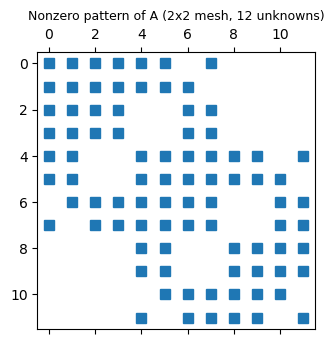

In [8]:
fig, ax = plt.subplots(figsize=(4, 3.6))
ax.spy(A_s, markersize=7)
ax.set_title("Nonzero pattern of A (2x2 mesh, 12 unknowns)", fontsize=9)
plt.show()

In [9]:
x_direct = {
    "PA = LU":  lu_solve(lu_factor(A_s), b_s),
    "inverse":  inv(A_s) @ b_s,
    "Cholesky": cho_solve(cho_factor(A_s, lower=True), b_s),
}
nb = np.linalg.norm(b_s)
for name, x in x_direct.items():
    print(f"{name:9s} relative residual ||b - Ax|| / ||b|| = {np.linalg.norm(b_s - A_s @ x) / nb:.2e}")
d = small["d"].copy(); d[small["free"]] = x_direct["Cholesky"]
print("\nright-edge horizontal displacements [mm]:", d.reshape(-1, 2)[small["side"]["right"], 0] * 1e3)

PA = LU   relative residual ||b - Ax|| / ||b|| = 6.15e-16
inverse   relative residual ||b - Ax|| / ||b|| = 8.53e-16
Cholesky  relative residual ||b - Ax|| / ||b|| = 7.72e-16

right-edge horizontal displacements [mm]: [0.5112 0.4822 0.4678]


## 4. Solver comparison on a larger system (report §3–4)

A $20\times20$ mesh gives 840 unknowns. Every method uses the **same protocol**:

* the same $A$ and $\mathbf{b}$, starting guess $\mathbf{x}_0 = 0$;
* stop when the relative residual $\|\mathbf{b}-A\mathbf{x}_k\|/\|\mathbf{b}\| < 10^{-8}$, checked independently of each method's own stopping test;
* at most 20,000 iterations;
* timing is the best of 3 runs (timings depend on the machine; iteration counts do not).

| Method | Requirement on $A$ | Expectation here |
|---|---|---|
| Jacobi | $\rho(I - D_A^{-1}A) < 1$ | not guaranteed even for SPD |
| Damped Jacobi ($\omega = 0.5$) | $\omega < 2/\lambda_{\max}(D_A^{-1}A)$ | converges, slowly |
| Gauss–Seidel | SPD is sufficient | converges, slowly |
| Steepest descent (SD) | SPD | converges, rate set by $\kappa$ |
| Conjugate gradient (CG) | SPD | converges in $O(\sqrt{\kappa})$ iterations |
| CG with diagonal preconditioner (PCG) | SPD and SPD preconditioner | slightly faster than CG |
| MINRES | symmetric | works; it does not use positive definiteness |
| GMRES (no restart) | any nonsingular $A$ | works, but stores a growing basis |

($D_A$ is the diagonal of $A$.)

In [10]:
TOL, CAP = 1e-8, 20_000
METHODS = ["Jacobi", "Damped Jacobi", "Gauss-Seidel", "SD", "CG", "PCG (diagonal)", "MINRES", "GMRES (full)"]


def iterative(A, b, method, *, cap=CAP, tol=TOL, history=True):
    # Zero initial guess. Returns x, iterations, status, residual history.
    # GMRES history is its internal (Arnoldi) residual estimate; its final residual is checked separately.
    x = np.zeros_like(b); nb = np.linalg.norm(b)
    hist = [1.0] if history else []
    count, last = 0, x.copy()

    class TargetReached(Exception):
        pass

    def monitor(xk):
        nonlocal count, last
        count += 1
        if method == "MINRES" or history:
            rr = float(np.linalg.norm(b - A @ xk) / nb)
            if history: hist.append(rr)
            if method == "MINRES" and rr < tol:      # MINRES stops on the shared true-residual target
                last = xk.copy(); raise TargetReached

    def arnoldi(res):
        nonlocal count
        count += 1
        if history: hist.append(float(res))

    if method in {"CG", "PCG (diagonal)"}:
        M = diags(1 / A.diagonal()) if method.startswith("PCG") else None
        x, info = cg(A, b, rtol=tol, atol=0, maxiter=cap, M=M, callback=monitor)
        status = "target" if info == 0 else f"info={info}"
    elif method == "GMRES (full)":
        x, info = gmres(A, b, rtol=tol, atol=0, restart=A.shape[0], maxiter=cap,
                        callback=arnoldi, callback_type="legacy")
        status = "target" if info == 0 else f"info={info}"
    elif method == "MINRES":
        try:
            x, info = minres(A, b, rtol=0, maxiter=cap, callback=monitor)
            status = f"info={info}"
        except TargetReached:
            x, status = last, "target"
    else:
        Dg = A.diagonal()
        L = tril(A, format="csr") if method == "Gauss-Seidel" else None
        U = (A - L).tocsr() if L is not None else None
        r, status = b.copy(), "iteration cap"
        for count in range(1, cap + 1):
            if method == "Jacobi":          x += r / Dg
            elif method == "Damped Jacobi": x += 0.5 * r / Dg
            elif method == "Gauss-Seidel":  x = spsolve_triangular(L, b - U @ x, lower=True)
            elif method == "SD":            Ar = A @ r; x += ((r @ r) / (r @ Ar)) * r
            r = b - A @ x
            rr = float(np.linalg.norm(r) / nb)
            if history: hist.append(rr)
            if not np.isfinite(rr) or rr > 1e10: status = "diverged"; break
            if rr < tol: status = "target"; break
    return x, count, status, hist

Sanity check on a $2\times2$ SPD system with a known answer. Every method must recover $\mathbf{x} = (1,-2)$.

In [11]:
A_t = csr_matrix([[4.0, 1.0], [1.0, 3.0]]); x_t = np.array([1.0, -2.0])
for m in METHODS:
    x, k, s, _ = iterative(A_t, A_t @ x_t, m, cap=2000)
    assert np.linalg.norm(x - x_t) < 1e-7, m
print("all methods recover the known solution")

all methods recover the known solution


In [12]:
case = plate_case(20)
A, b = case["A"], case["b"]
lu = splu(A.tocsc()); x_ref = lu.solve(b)          # sparse direct reference solution
print(f"unknowns: {len(b)}, stored nonzeros: {A.nnz} ({100 * A.nnz / len(b)**2:.2f}% of the matrix)")
print(f"sparse LU reference: relative residual {np.linalg.norm(b - A @ x_ref) / np.linalg.norm(b):.1e}")

TIMING_RUNS = 3
rows, histories = [], {}
for m in METHODS:
    x, k, status, hist = iterative(A, b, m)
    histories[m] = hist
    times = []
    for _ in range(TIMING_RUNS):
        t0 = perf_counter(); iterative(A, b, m, history=False); times.append(perf_counter() - t0)
    rr = np.linalg.norm(b - A @ x) / np.linalg.norm(b)
    err = np.linalg.norm(x - x_ref) / np.linalg.norm(x_ref)
    rows.append((m, k, status, rr, err, min(times)))

print(f"\n{'method':16s} {'iterations':>10s} {'status':>14s} {'rel. residual':>14s} {'rel. error':>11s} {'best time [s]':>14s}")
for m, k, s, rr, err, tm in rows:
    print(f"{m:16s} {k:10d} {s:>14s} {rr:14.2e} {err:11.2e} {tm:14.4f}")

unknowns: 840, stored nonzeros: 11112 (1.57% of the matrix)
sparse LU reference: relative residual 3.1e-14



method           iterations         status  rel. residual  rel. error  best time [s]
Jacobi                   49       diverged       1.32e+10    3.38e+07         0.0006
Damped Jacobi         20000  iteration cap       4.76e-06    8.73e-05         0.2228
Gauss-Seidel          19136         target       1.00e-08    1.74e-07        78.2805
SD                    20000  iteration cap       3.08e-06    4.22e-05         0.3870
CG                      242         target       9.23e-09    9.71e-10         0.0038
PCG (diagonal)          226         target       8.40e-09    4.85e-10         0.0045
MINRES                  236         target       9.66e-09    6.14e-09         0.0084
GMRES (full)            228         target       9.48e-09    5.97e-09         0.1986


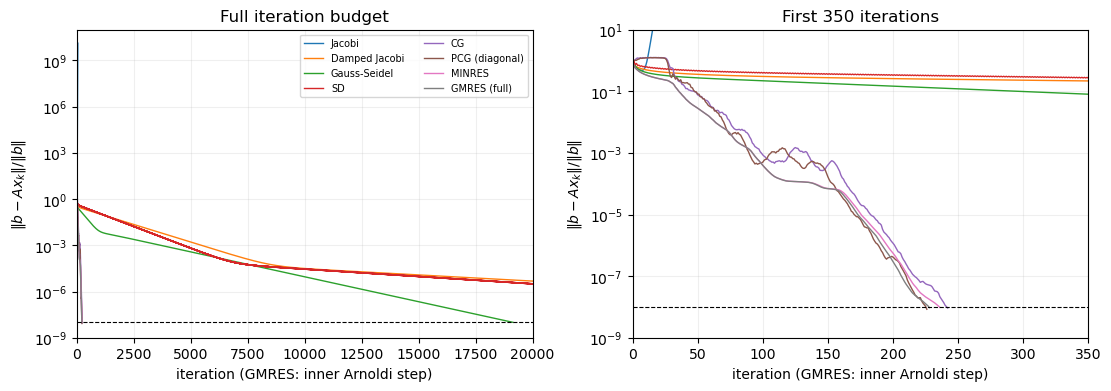

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), constrained_layout=True)
for name, hist in histories.items():
    for ax in axes:
        ax.semilogy(range(len(hist)), hist, label=name, lw=1)
for ax in axes:
    ax.axhline(TOL, color="black", ls="--", lw=0.8)
    ax.set_xlabel("iteration (GMRES: inner Arnoldi step)"); ax.set_ylabel(r"$\|b-Ax_k\|/\|b\|$"); ax.grid(alpha=0.2)
axes[0].set(xlim=(0, CAP), ylim=(1e-9, 1e11), title="Full iteration budget")
axes[1].set(xlim=(0, 350), ylim=(1e-9, 10), title="First 350 iterations")
axes[0].legend(fontsize=7, ncol=2)
plt.show()

**Why Jacobi diverges although $A$ is SPD.** Jacobi converges exactly when the spectral radius $\rho(I - D_A^{-1}A) < 1$. Since $D_A^{-1}A$ is similar to the SPD matrix $S = D_A^{-1/2} A D_A^{-1/2}$, its eigenvalues are real and positive. So $\rho = \max(|1-\lambda_{\min}(S)|, |1-\lambda_{\max}(S)|)$, and Jacobi fails as soon as $\lambda_{\max}(S) > 2$.

In [14]:
H = diags(1 / np.sqrt(A.diagonal()))
S = (H @ A @ H).tocsr()
s_lo = eigsh(S, k=1, which="SA", return_eigenvectors=False, tol=1e-10, v0=np.ones(len(b)))[0]
s_hi = eigsh(S, k=1, which="LA", return_eigenvectors=False, tol=1e-10, v0=np.ones(len(b)))[0]
print(f"lambda(S) in [{s_lo:.4f}, {s_hi:.4f}]")
print(f"Jacobi spectral radius rho = {max(abs(1 - s_lo), abs(1 - s_hi)):.4f}  (> 1: diverges)")
print(f"damped Jacobi converges for omega < 2 / lambda_max(S) = {2 / s_hi:.4f}  (we use 0.5)")

lambda(S) in [0.0004, 2.9601]
Jacobi spectral radius rho = 1.9601  (> 1: diverges)
damped Jacobi converges for omega < 2 / lambda_max(S) = 0.6757  (we use 0.5)


## 5. Mesh refinement: conditioning and solver effort (report §4)

Halving the cell size $h$ should multiply the condition number by about 4 ($\kappa = O(h^{-2})$). Since CG needs $O(\sqrt{\kappa})$ iterations, its iteration count should roughly double each time.

In [15]:
def extreme_eigs(A):
    # Smallest eigenvalue by shift-invert around 0 (fast with a sparse factorisation), largest directly.
    lo = eigsh(A.tocsc(), k=1, sigma=0, which="LM", return_eigenvectors=False)[0]
    hi = eigsh(A, k=1, which="LA", return_eigenvectors=False, tol=1e-10, v0=np.ones(A.shape[0]))[0]
    return lo, hi

refine = []
for n in (10, 20, 40):
    c_n = plate_case(n)
    lo, hi = extreme_eigs(c_n["A"])
    _, k_cg, _, _ = iterative(c_n["A"], c_n["b"], "CG", history=False)
    d_n = c_n["d"].copy(); d_n[c_n["free"]] = splu(c_n["A"].tocsc()).solve(c_n["b"])
    top_right = c_n["side"]["right"][-1]
    refine.append((n, len(c_n["b"]), c_n["A"].nnz, hi / lo, k_cg, d_n[2 * top_right] * 1e3))

print(f"{'cells':>6s} {'unknowns':>9s} {'nnz':>7s} {'kappa':>10s} {'CG its':>7s} {'u_x top-right [mm]':>19s}")
for r in refine:
    print(f"{r[0]:4d}^2 {r[1]:9d} {r[2]:7d} {r[3]:10.0f} {r[4]:7d} {r[5]:19.5f}")
print("kappa ratios:", [f"{refine[i+1][3] / refine[i][3]:.2f}" for i in range(2)],
      "| CG ratios:", [f"{refine[i+1][4] / refine[i][4]:.2f}" for i in range(2)])

 cells  unknowns     nnz      kappa  CG its  u_x top-right [mm]
  10^2       220    2752       2469     120             0.49385
  20^2       840   11112       9104     242             0.49551
  40^2      3280   44632      34548     469             0.49607
kappa ratios: ['3.69', '3.79'] | CG ratios: ['2.02', '1.94']


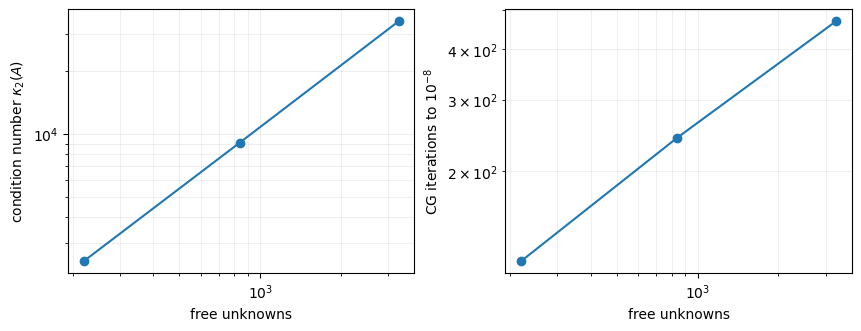

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(8.5, 3.2), constrained_layout=True)
ns = [r[1] for r in refine]
axes[0].loglog(ns, [r[3] for r in refine], "o-"); axes[0].set_ylabel(r"condition number $\kappa_2(A)$")
axes[1].loglog(ns, [r[4] for r in refine], "o-"); axes[1].set_ylabel("CG iterations to $10^{-8}$")
for ax in axes:
    ax.set_xlabel("free unknowns"); ax.grid(alpha=0.2, which="both")
plt.show()

## 6. Validation (report §4)

"All solvers agree" only shows that the *linear system* was solved correctly. To check the *model* we test:

1. **Equilibrium.** Support reactions plus applied loads must sum to zero force and zero moment.
2. **An exact solution.** With a roller support (only $u_x = 0$ on the left edge, plus $u_y = 0$ at one corner) the plate is in uniform tension. The exact displacement $u_x = p\,x/E$, $u_y = -\nu\,p\,y/E$ is linear, so linear triangles must reproduce it to rounding error.
3. **Sensitivity.** A relative perturbation of $10^{-6}$ in $\mathbf{b}$ may change $\mathbf{x}$ by at most $\kappa \cdot 10^{-6}$ (relative).

In [17]:
def equilibrium(case, x):
    d = case["d"].copy(); d[case["free"]] = x
    r = case["K"] @ d - case["f"]                         # nonzero only at supports: the reactions
    reac = np.zeros_like(r); reac[case["constrained"]] = r[case["constrained"]]
    total = (reac + case["f"]).reshape(-1, 2)
    xy = case["nodes"]
    return d, total.sum(axis=0), float(np.sum(xy[:, 0] * total[:, 1] - xy[:, 1] * total[:, 0]))

d20, F_net, M_net = equilibrium(case, x_ref)
print(f"applied load: {case['f'].reshape(-1, 2).sum(axis=0)} N")
print(f"net force  (loads + reactions): {F_net} N")
print(f"net moment (loads + reactions): {M_net:.2e} N m")

roller = plate_case(6, 4, Lx=2.0, Ly=1.0, support="roller")
d_r = roller["d"].copy(); d_r[roller["free"]] = splu(roller["A"].tocsc()).solve(roller["b"])
exact = np.column_stack([P * roller["nodes"][:, 0] / E, -NU * P * roller["nodes"][:, 1] / E]).ravel()
print(f"\nroller test: relative error vs exact solution = {np.linalg.norm(d_r - exact) / np.linalg.norm(exact):.1e}")

rng = np.random.default_rng(2026)
db = rng.normal(size=len(b)); db *= 1e-6 * np.linalg.norm(b) / np.linalg.norm(db)
dx = lu.solve(b + db) - x_ref
lo20, hi20 = extreme_eigs(A)
print(f"\nperturbation: ||db||/||b|| = 1e-6 -> ||dx||/||x|| = {np.linalg.norm(dx) / np.linalg.norm(x_ref):.2e}"
      f"  (bound kappa * 1e-6 = {hi20 / lo20 * 1e-6:.2e})")

applied load: [1000000.       0.] N
net force  (loads + reactions): [-9.1313e-10 -2.9140e-09] N
net moment (loads + reactions): 5.97e-09 N m

roller test: relative error vs exact solution = 7.9e-16

perturbation: ||db||/||b|| = 1e-6 -> ||dx||/||x|| = 4.51e-07  (bound kappa * 1e-6 = 9.10e-03)


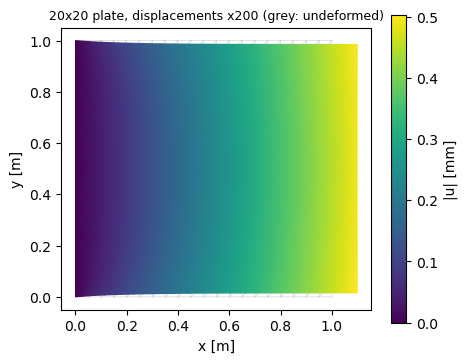

maximum right-edge u_x = 0.4967 mm


In [18]:
def plot_deformed(ax, nodes, tris, d, scale, title):
    u = d.reshape(-1, 2)
    ax.triplot(nodes[:, 0], nodes[:, 1], tris, color="0.8", lw=0.4)
    tp = ax.tripcolor(*(nodes + scale * u).T, tris, np.linalg.norm(u, axis=1) * 1e3, shading="gouraud", cmap="viridis")
    ax.set_aspect("equal"); ax.set_title(title, fontsize=9); ax.set_xlabel("x [m]"); ax.set_ylabel("y [m]")
    return tp

fig, ax = plt.subplots(figsize=(5, 4))
tp = plot_deformed(ax, case["nodes"], case["triangles"], d20, 200, "20x20 plate, displacements x200 (grey: undeformed)")
fig.colorbar(tp, ax=ax, label="|u| [mm]")
plt.show()
print(f"maximum right-edge u_x = {d20.reshape(-1, 2)[case['side']['right'], 0].max() * 1e3:.4f} mm")

## 7. Other objects and experiments (report §5–6)

> **Status:** this part implements the case specification proposed in report §5 (`cases.json` on branch `docs/section5-initial-draft`), which is embedded below. The group has not yet approved that specification, so these results are provisional until it is.

Three objects share the baseline material, thickness, clamp and traction:

* **S**: the unit square (control);
* **R**: a $2\times1$ m rectangle (the load is farther from the clamp);
* **H**: the unit square with a central $0.2\times0.2$ m opening.

Meshes come from **Triangle** (`p`: respect the boundary polygon, `q25`: minimum angle 25°, `a`: maximum triangle area). Boundary split points are inserted on the left and right edges, so the load patches and the partial clamp start and end exactly at nodes.

In [19]:
CASES = json.loads(r'''{
 "status": "PROPOSED, NOT APPROVED OR EXECUTED",
 "units": {
  "length": "m",
  "force": "N",
  "stress": "Pa"
 },
 "baseline": {
  "model": "plane stress, homogeneous isotropic linear elasticity",
  "E_Pa": 200000000000.0,
  "nu": 0.3,
  "thickness_m": 0.01,
  "body_force": [
   0,
   0
  ],
  "prescribed_displacement_m": [
   0,
   0
  ],
  "support": "ux=uy=0 along the whole left edge",
  "loaded_edge": "whole right edge",
  "traction_Pa": [
   100000000.0,
   0
  ],
  "total_force_N": [
   1000000.0,
   0
  ],
  "other_edges": "traction free, including hole"
 },
 "objects": [
  {
   "id": "S",
   "name": "square control",
   "outer_ccw_m": [
    [
     0.0,
     0.0
    ],
    [
     1.0,
     0.0
    ],
    [
     1.0,
     1.0
    ],
    [
     0.0,
     1.0
    ]
   ],
   "holes_cw_m": [],
   "hole_seeds_m": [],
   "left_x_m": 0.0,
   "right_x_m": 1.0,
   "left_boundary_splits_y_m": [
    0.0,
    0.25,
    0.75,
    1.0
   ],
   "right_boundary_splits_y_m": [
    0.0,
    0.25,
    0.375,
    0.5,
    0.625,
    0.75,
    1.0
   ]
  },
  {
   "id": "R",
   "name": "long rectangle",
   "outer_ccw_m": [
    [
     0.0,
     0.0
    ],
    [
     2.0,
     0.0
    ],
    [
     2.0,
     1.0
    ],
    [
     0.0,
     1.0
    ]
   ],
   "holes_cw_m": [],
   "hole_seeds_m": [],
   "left_x_m": 0.0,
   "right_x_m": 2.0,
   "left_boundary_splits_y_m": [
    0.0,
    0.25,
    0.75,
    1.0
   ],
   "right_boundary_splits_y_m": [
    0.0,
    0.25,
    0.375,
    0.5,
    0.625,
    0.75,
    1.0
   ]
  },
  {
   "id": "H",
   "name": "square with central opening",
   "outer_ccw_m": [
    [
     0.0,
     0.0
    ],
    [
     1.0,
     0.0
    ],
    [
     1.0,
     1.0
    ],
    [
     0.0,
     1.0
    ]
   ],
   "holes_cw_m": [
    [
     [
      0.4,
      0.4
     ],
     [
      0.4,
      0.6
     ],
     [
      0.6,
      0.6
     ],
     [
      0.6,
      0.4
     ]
    ]
   ],
   "hole_seeds_m": [
    [
     0.5,
     0.5
    ]
   ],
   "left_x_m": 0.0,
   "right_x_m": 1.0,
   "left_boundary_splits_y_m": [
    0.0,
    0.25,
    0.75,
    1.0
   ],
   "right_boundary_splits_y_m": [
    0.0,
    0.25,
    0.375,
    0.5,
    0.625,
    0.75,
    1.0
   ]
  }
 ],
 "meshing": {
  "generator": "Python triangle interface, constrained polygon triangulation",
  "implementation_status": "not yet implemented or executed by this drafting task",
  "minimum_angle_requested_deg": 25,
  "max_triangle_area_m2": [
   0.005,
   0.00125,
   0.0003125
  ],
  "options": [
   "pq25a0.005",
   "pq25a0.00125",
   "pq25a0.0003125"
  ],
  "default_max_triangle_area_m2": 0.00125,
  "notes": [
   "Insert all listed boundary split points as constrained segment endpoints on every mesh, even for baseline cases.",
   "Preserve polygon vertices and empty holes; permit boundary subdivision.",
   "Refinements are not assumed nested. Archive generated nodes, elements, markers, mesher version, options and actual quality.",
   "Reuse identical nodes/elements for load and support variants."
  ]
 },
 "studies": {
  "geometry": {
   "objects": [
    "S",
    "R",
    "H"
   ],
   "fixed": "baseline physical settings and middle mesh-area limit"
  },
  "mesh": {
   "objects": [
    "S",
    "R",
    "H"
   ],
   "areas_m2": [
    0.005,
    0.00125,
    0.0003125
   ],
   "fixed": "baseline physical case on each object"
  },
  "magnitude": {
   "objects": [
    "S",
    "R",
    "H"
   ],
   "force_factors": [
    0.5,
    1,
    1.5
   ],
   "fixed": "same mesh, full right edge and full clamp"
  },
  "location": {
   "objects": [
    "S",
    "R",
    "H"
   ],
   "right_edge_intervals_y_m": [
    [
     0,
     0.25
    ],
    [
     0.375,
     0.625
    ],
    [
     0.75,
     1
    ]
   ],
   "force_N": [
    1000000.0,
    0
   ],
   "patch_traction_Pa": [
    400000000.0,
    0
   ],
   "fixed": "same mesh, full clamp and equal patch length"
  },
  "supports": {
   "objects": [
    "S",
    "R",
    "H"
   ],
   "left_clamp_intervals_y_m": [
    [
     0,
     1
    ],
    [
     0.25,
     0.75
    ]
   ],
   "constrained_components": [
    "ux",
    "uy"
   ],
   "fixed": "same mesh and full-edge baseline load"
  }
 },
 "observables": {
  "mean_right_ux": "Integral of ux over the entire right edge divided by its length; integrate the piecewise linear boundary trace.",
  "right_midpoint": "Evaluate ux and uy at (right_x, 0.5) m.",
  "solver_metrics": "Reuse current Section 3 without changing timing, stopping, method set or counting conventions.",
  "conditioning": "Section 2 eigenvalue estimates and defects; report failures.",
  "validation": "Mesh geometry, supported symmetry/positive definiteness, prescribed values, constrained reactions, global force and moment balance, same-mesh reference residual.",
  "not_results": "No mesh, displacement, timing or convergence output is supplied by this specification.",
  "solution_source": "Checked same-mesh sparse-LU reference, not an unconverged iterative approximation; deformed outlines use this reference too.",
  "refinement_comparison": {
   "outputs": [
    "mean right-edge ux",
    "right-midpoint ux",
    "right-midpoint uy"
   ],
   "statistic": "Absolute differences in metres between consecutive area-limit levels; retain both signed values as well.",
   "relative_difference": "Not used by default, avoiding division by zero or nearly zero midpoint components. Any optional scaled metric must state its nonzero physical scale.",
   "algebraic_uncertainty": "For each scalar observable w^T x, estimate uncertainty as ||w||_2 ||b-Ax_ref||_2 / lambda_min_est using its actual interpolation or edge-integration weights. Compare the mesh difference with the sum of estimates from the two meshes. This estimate is not a certified bound unless lambda_min has a certified lower bound; it omits assembly and modelling uncertainty.",
   "resolution_rule": "Report differences at or below the summed algebraic estimates as unresolved; do not infer a convergence rate from them. A missing/unreliable eigenvalue estimate leaves this resolution check unverified. If the comparison depends on differences near these estimates, confirm with a higher-precision reference before drawing a conclusion."
  }
 },
 "proposed_acceptance": {
  "status": "Proposed execution criteria, not implemented or passed tests; not derived from Section 4 observed imbalances.",
  "symmetry": {
   "metric": "||A-A^T||_F / ||A||_F",
   "threshold": 1e-12,
   "guard": "Require finite positive denominator."
  },
  "positive_definiteness": {
   "structural": "Check positive thickness, admissible material, nondegenerate conforming triangles, edge-connected solid and constraints removing all three planar rigid motions. This supplies the structural SPD argument.",
   "small_systems": "For at most 2000 free components, additionally require successful dense Cholesky of the supported matrix after symmetry check.",
   "large_systems": "Compute smallest algebraic eigenpair with eigsh(which=SA). Require reported convergence, normalized eigenpair defect <= 1e-8, and lambda_est > 10*||A v-lambda_est v||_2/||v||_2. This is a diagnostic supporting the structural argument, not a certified proof of lambda_min.",
   "defect": "||A v-lambda_est v||_2 / (||A||_inf ||v||_2)",
   "failure": "Failed/nonconverged diagnostics mean unverified; do not silently treat them as passed or automatically equate eigensolver failure with indefiniteness."
  },
  "reference_residual": {
   "metric": "||b-A x_ref||_2 / ||b||_2",
   "threshold_strict": 1e-08,
   "guard": "All proposed cases have nonzero b; use original unrounded arrays."
  },
  "supports": {
   "metric": "max absolute prescribed displacement discrepancy, metres",
   "threshold_m": 1e-12,
   "scope": "All prescribed components, which are zero in these cases."
  },
  "force_balance": {
   "metric": "||sum_i(f_i+r_i)||_2 / sum_i ||f_i||_2",
   "threshold": 1e-08,
   "reaction_scope": "r is nonzero only at constrained components; include all original applied loads, including those at constrained components."
  },
  "moment_balance": {
   "origin_m": [
    0,
    0
   ],
   "metric": "|sum_i [x_i*(f_yi+r_yi)-y_i*(f_xi+r_xi)]| / (L_char * sum_i ||f_i||_2)",
   "L_char": "Bounding-box diagonal in metres of the undeformed object.",
   "threshold": 1e-08,
   "guard": "Do not normalize by the net applied moment, which can vanish. Force scale must be positive."
  },
  "outcome": "Record each check separately. Do not admit a failed or unverified reference into physical/refinement plots as validated. Solver failure records still belong in solver comparisons."
 }
}''')
OBJECTS = {o['id']: o for o in CASES['objects']}
AREAS = CASES['meshing']['max_triangle_area_m2']
print(CASES['status']); print({k: v['name'] for k, v in OBJECTS.items()}); print('max triangle areas:', AREAS)

PROPOSED, NOT APPROVED OR EXECUTED
{'S': 'square control', 'R': 'long rectangle', 'H': 'square with central opening'}
max triangle areas: [0.005, 0.00125, 0.0003125]


In [20]:
def polygon_with_splits(obj):
    # Outer boundary (CCW) with the left/right split points inserted, as a closed vertex loop.
    xl, xr = obj["left_x_m"], obj["right_x_m"]
    (x0, y0), _, _, (_, y1) = obj["outer_ccw_m"]
    right = [(xr, y) for y in obj["right_boundary_splits_y_m"]]            # bottom to top
    left = [(xl, y) for y in obj["left_boundary_splits_y_m"]][::-1]        # top to bottom
    loop = right + left
    return np.array(loop[:-1] if np.allclose(loop[0], loop[-1]) else loop)


def mesh_object(obj, max_area, min_angle=25):
    outer = polygon_with_splits(obj)
    verts, segs = [outer], [np.column_stack([np.arange(len(outer)), np.roll(np.arange(len(outer)), -1)])]
    for hole in obj["holes_cw_m"]:
        h = np.array(hole); start = sum(len(v) for v in verts)
        verts.append(h); segs.append(start + np.column_stack([np.arange(len(h)), np.roll(np.arange(len(h)), -1)]))
    geom = dict(vertices=np.vstack(verts), segments=np.vstack(segs))
    if obj["hole_seeds_m"]:
        geom["holes"] = np.array(obj["hole_seeds_m"])
    m = tr.triangulate(geom, f"pq{min_angle}a{max_area}")
    nodes, tris = m["vertices"], m["triangles"]
    # orient every triangle counter-clockwise
    a = nodes[tris]
    two_area = (a[:, 1, 0] - a[:, 0, 0]) * (a[:, 2, 1] - a[:, 0, 1]) - (a[:, 2, 0] - a[:, 0, 0]) * (a[:, 1, 1] - a[:, 0, 1])
    tris = np.where((two_area < 0)[:, None], tris[:, [0, 2, 1]], tris)
    return nodes, tris


def boundary_edges(tris):
    e = np.sort(np.vstack([tris[:, [0, 1]], tris[:, [1, 2]], tris[:, [2, 0]]]), axis=1)
    uniq, counts = np.unique(e, axis=0, return_counts=True)
    return uniq[counts == 1]


def mesh_checks(obj, nodes, tris):
    a = nodes[tris]
    two_area = (a[:, 1, 0] - a[:, 0, 0]) * (a[:, 2, 1] - a[:, 0, 1]) - (a[:, 2, 0] - a[:, 0, 0]) * (a[:, 1, 1] - a[:, 0, 1])
    area_total = two_area.sum() / 2
    cent = a.mean(axis=1)
    in_hole = 0
    for hole in obj["holes_cw_m"]:
        h = np.array(hole)
        in_hole += np.sum((cent[:, 0] > h[:, 0].min()) & (cent[:, 0] < h[:, 0].max()) &
                          (cent[:, 1] > h[:, 1].min()) & (cent[:, 1] < h[:, 1].max()))
    # smallest interior angle
    ang = []
    for i in range(3):
        u, v = a[:, (i + 1) % 3] - a[:, i], a[:, (i + 2) % 3] - a[:, i]
        ang.append(np.degrees(np.arccos(np.clip(np.sum(u * v, 1) / np.linalg.norm(u, axis=1) / np.linalg.norm(v, axis=1), -1, 1))))
    return dict(nodes=len(nodes), triangles=len(tris), min_signed_area=two_area.min() / 2,
                material_area=area_total, centroids_in_hole=int(in_hole), min_angle_deg=float(np.min(ang)))

**Loads and supports on a general mesh.** A load *patch* is an interval $[y_0, y_1]$ of the right edge carrying total force $F$. Its traction is $F/(t\,(y_1-y_0))$, applied to the boundary edges inside the patch. A *clamp* fixes both components at every left-edge node with $y\in[y_0,y_1]$.

In [21]:
def object_case(obj, nodes, tris, *, load_y=(0.0, 1.0), force=1e6, clamp_y=(0.0, 1.0)):
    xl, xr, tol = obj["left_x_m"], obj["right_x_m"], 1e-9
    K = assemble(nodes, tris, E, NU, T)
    be = boundary_edges(tris)
    on_right = np.all(np.abs(nodes[be][:, :, 0] - xr) < tol, axis=1)
    mid_y = nodes[be][:, :, 1].mean(axis=1)
    right_edges = be[on_right]
    patch = right_edges[(mid_y[on_right] > load_y[0]) & (mid_y[on_right] < load_y[1])]
    traction = force / (T * (load_y[1] - load_y[0]))
    f = constant_edge_load(nodes, patch, [T * traction, 0.0])
    clamp_nodes = np.where((np.abs(nodes[:, 0] - xl) < tol) & (nodes[:, 1] > clamp_y[0] - tol) & (nodes[:, 1] < clamp_y[1] + tol))[0]
    c = np.sort(xy_dofs(clamp_nodes))
    A, b, free, d = reduce_system(K, f, c, np.zeros(c.size))
    return dict(nodes=nodes, triangles=tris, K=K, f=f, constrained=c, free=free, d=d, A=A, b=b,
                right_edges=right_edges, clamp_nodes=clamp_nodes, traction=traction)


def responses(obj, case, d):
    # Edge-length-weighted mean right-edge u_x, and both components at the right-edge midpoint (x_r, 0.5).
    u = d.reshape(-1, 2); n = case["nodes"]; e = case["right_edges"]
    L = np.linalg.norm(n[e[:, 1]] - n[e[:, 0]], axis=1)
    mean_ux = np.sum(L * u[e].mean(axis=1)[:, 0]) / L.sum()
    mid = np.argmin(np.linalg.norm(n - [obj["right_x_m"], 0.5], axis=1))
    return dict(mean_right_ux_mm=mean_ux * 1e3, mid_ux_mm=u[mid, 0] * 1e3, mid_uy_mm=u[mid, 1] * 1e3)


def observable_weights(obj, case):
    # Each response is a linear functional w^T d of the displacement vector (metres).
    n, e = case["nodes"], case["right_edges"]
    L = np.linalg.norm(n[e[:, 1]] - n[e[:, 0]], axis=1)
    w_mean = np.zeros(2 * len(n))
    for end in (0, 1):
        np.add.at(w_mean, 2 * e[:, end], L / 2 / L.sum())        # trapezoid rule on the piecewise-linear trace
    mid = np.argmin(np.linalg.norm(n - [obj["right_x_m"], 0.5], axis=1))
    w_ux, w_uy = np.zeros(2 * len(n)), np.zeros(2 * len(n))
    w_ux[2 * mid], w_uy[2 * mid + 1] = 1.0, 1.0
    return {"mean_right_ux": w_mean, "mid_ux": w_ux, "mid_uy": w_uy}

**Acceptance checks** (report §5, proposed thresholds). Every solved case must pass all of them before its results are used:

| Check | Metric | Threshold |
|---|---|---|
| symmetry | $\|A-A^\top\|_F/\|A\|_F$ | $\le 10^{-12}$ |
| positive definiteness | dense Cholesky succeeds (≤ 2000 unknowns); otherwise the smallest eigenpair $(\lambda, v)$ has defect $\|Av-\lambda v\|/(\|A\|_\infty\|v\|) \le 10^{-8}$ and $\lambda > 10\,\|Av-\lambda v\|/\|v\|$ | |
| reference residual | $\|b-Ax_{\rm ref}\|/\|b\|$ (sparse LU) | $\le 10^{-8}$ |
| supports | largest prescribed-displacement discrepancy | $\le 10^{-12}$ m |
| force balance | $\|\sum_i(\mathbf f_i+\mathbf r_i)\| / \sum_i\|\mathbf f_i\|$ | $\le 10^{-8}$ |
| moment balance | $|\sum_i x_i(f+r)_{y,i} - y_i(f+r)_{x,i}| / (L_{\rm char}\sum_i\|\mathbf f_i\|)$, $L_{\rm char}$ = bounding-box diagonal | $\le 10^{-8}$ |

**Algebraic uncertainty.** A response $w^\top\mathbf d$ computed from an inexact solution has error at most about $\|w\|_2\,\|b-Ax_{\rm ref}\|_2/\lambda_{\min}$. A mesh-to-mesh difference no larger than the sum of the two meshes' estimates is reported as *unresolved*.

(The smallest eigenvalue is computed by shift-invert around 0, which returns the same eigenpair as `which="SA"`, only faster.)

In [22]:
from scipy.linalg import cholesky, LinAlgError
from scipy.sparse.linalg import norm as spnorm

def acceptance(case, x):
    A, b = case["A"], case["b"]
    out = {}
    out["symmetry"] = spnorm(A - A.T, "fro") / spnorm(A, "fro")
    lam, v = eigsh(A.tocsc(), k=1, sigma=0, which="LM")
    lam, v = lam[0], v[:, 0]
    res = np.linalg.norm(A @ v - lam * v)
    out["lambda_min"] = lam
    if A.shape[0] <= 2000:
        try:
            cholesky(A.toarray()); spd = True
        except LinAlgError:
            spd = False
    else:
        spd = res / (spnorm(A, np.inf) * np.linalg.norm(v)) <= 1e-8 and lam > 10 * res / np.linalg.norm(v)
    out["spd"] = bool(spd)
    out["residual"] = np.linalg.norm(b - A @ x) / np.linalg.norm(b)
    d, F_net, M_net = equilibrium(case, x)
    out["supports_m"] = float(np.abs(d[case["constrained"]]).max())
    f_scale = np.linalg.norm(case["f"].reshape(-1, 2), axis=1).sum()
    lo, hi = case["nodes"].min(axis=0), case["nodes"].max(axis=0)
    out["force_balance"] = np.linalg.norm(F_net) / f_scale
    out["moment_balance"] = abs(M_net) / (np.linalg.norm(hi - lo) * f_scale)
    out["passed"] = bool(out["symmetry"] <= 1e-12 and spd and out["residual"] <= 1e-8 and out["supports_m"] <= 1e-12
                         and out["force_balance"] <= 1e-8 and out["moment_balance"] <= 1e-8)
    return d, out


ACCEPTANCE_LOG = []

def solve_object(obj, case, *, conditioning=False, label=""):
    A, b = case["A"], case["b"]
    x = splu(A.tocsc()).solve(b)                     # checked same-mesh LU reference
    d, acc = acceptance(case, x)
    ACCEPTANCE_LOG.append((f"{obj['id']} {label}", acc))
    out = dict(unknowns=len(b), acceptance=acc, **responses(obj, case, d))
    # algebraic uncertainty of each response, in mm
    r_norm = np.linalg.norm(b - A @ x)
    for name, w in observable_weights(obj, case).items():
        out["unc_" + name + "_mm"] = np.linalg.norm(w[case["free"]]) * r_norm / acc["lambda_min"] * 1e3
    out["cg_iterations"] = iterative(A, b, "CG", history=False)[1]
    out["pcg_iterations"] = iterative(A, b, "PCG (diagonal)", history=False)[1]
    if conditioning:
        lo, hi = extreme_eigs(A); out["kappa"] = hi / lo
    return d, out

### 7.1 Meshes

S area<=0.005     nodes   173 triangles   309 material area 1.0000 m^2  min angle 25.9 deg  centroids in hole 0
S area<=0.00125   nodes   659 triangles  1247 material area 1.0000 m^2  min angle 25.9 deg  centroids in hole 0
S area<=0.0003125 nodes  2600 triangles  5046 material area 1.0000 m^2  min angle 25.3 deg  centroids in hole 0
R area<=0.005     nodes   354 triangles   651 material area 2.0000 m^2  min angle 25.0 deg  centroids in hole 0
R area<=0.00125   nodes  1285 triangles  2460 material area 2.0000 m^2  min angle 25.5 deg  centroids in hole 0


R area<=0.0003125 nodes  5120 triangles 10018 material area 2.0000 m^2  min angle 25.1 deg  centroids in hole 0
H area<=0.005     nodes   173 triangles   302 material area 0.9600 m^2  min angle 25.0 deg  centroids in hole 0
H area<=0.00125   nodes   643 triangles  1192 material area 0.9600 m^2  min angle 25.0 deg  centroids in hole 0
H area<=0.0003125 nodes  2473 triangles  4767 material area 0.9600 m^2  min angle 25.4 deg  centroids in hole 0


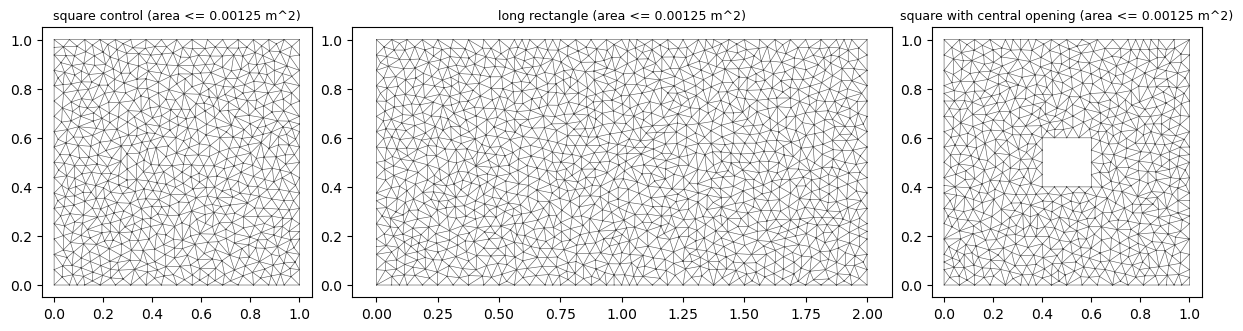

In [23]:
meshes = {}
for oid, obj in OBJECTS.items():
    for a in AREAS:
        meshes[oid, a] = mesh_object(obj, a)
        chk = mesh_checks(obj, *meshes[oid, a])
        print(f"{oid} area<={a:<9g} nodes {chk['nodes']:5d} triangles {chk['triangles']:5d} "
              f"material area {chk['material_area']:.4f} m^2  min angle {chk['min_angle_deg']:.1f} deg  "
              f"centroids in hole {chk['centroids_in_hole']}")
        assert chk["min_signed_area"] > 0 and chk["centroids_in_hole"] == 0
MID = CASES["meshing"]["default_max_triangle_area_m2"]

fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), gridspec_kw=dict(width_ratios=[1, 2, 1]), constrained_layout=True)
for ax, oid in zip(axes, OBJECTS):
    nodes, tris = meshes[oid, MID]
    ax.triplot(nodes[:, 0], nodes[:, 1], tris, lw=0.4, color="0.3")
    ax.set_aspect("equal"); ax.set_title(f"{OBJECTS[oid]['name']} (area <= {MID} m^2)", fontsize=9)
plt.show()

### 7.2 Geometry study

Baseline load and clamp, middle mesh. This compares deformation and solver effort across the three shapes.

In [24]:
base = {}
for oid, obj in OBJECTS.items():
    cs = object_case(obj, *meshes[oid, MID])
    d, out = solve_object(obj, cs, conditioning=True, label="geometry")
    base[oid] = (cs, d, out)

hdr = f"{'object':28s} {'unknowns':>8s} {'kappa':>9s} {'CG':>5s} {'PCG':>5s} {'mean u_x right [mm]':>20s} {'mid u_x [mm]':>12s} {'mid u_y [mm]':>12s} {'checks':>7s}"
print(hdr)
for oid, (cs, d, o) in base.items():
    print(f"{OBJECTS[oid]['name']:28s} {o['unknowns']:8d} {o['kappa']:9.0f} {o['cg_iterations']:5d} {o['pcg_iterations']:5d} "
          f"{o['mean_right_ux_mm']:20.5f} {o['mid_ux_mm']:12.5f} {o['mid_uy_mm']:12.2e} {'pass' if o['acceptance']['passed'] else 'FAIL':>7s}")

object                       unknowns     kappa    CG   PCG  mean u_x right [mm] mid u_x [mm] mid u_y [mm]  checks
square control                   1282     11240   268   245              0.49363      0.49178    -5.66e-06    pass
long rectangle                   2532    100758   427   395              0.99362      0.99365     2.53e-05    pass
square with central opening      1246     13032   283   256              0.55597      0.58825     4.03e-04    pass


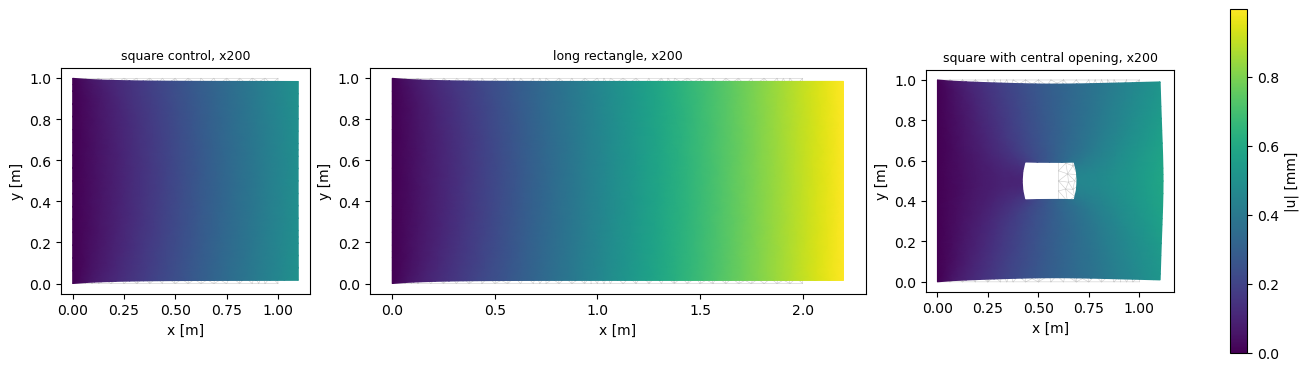

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), gridspec_kw=dict(width_ratios=[1, 2, 1]), constrained_layout=True)
vmax = max(np.linalg.norm(d.reshape(-1, 2), axis=1).max() for _, d, _ in base.values()) * 1e3
for ax, (oid, (cs, d, o)) in zip(axes, base.items()):
    tp = plot_deformed(ax, cs["nodes"], cs["triangles"], d, 200, f"{OBJECTS[oid]['name']}, x200")
    tp.set_clim(0, vmax)
fig.colorbar(tp, ax=axes, label="|u| [mm]")
plt.show()

### 7.3 Mesh study

The same physical case on three meshes per object. Meshes are not nested, so we report the **successive differences** of each response. These measure mesh dependence, not the error against an exact solution.

In [26]:
mesh_study = {}
for oid, obj in OBJECTS.items():
    for a in AREAS:
        cs = object_case(obj, *meshes[oid, a])
        _, mesh_study[oid, a] = solve_object(obj, cs, conditioning=True, label=f"mesh a={a}")

OBS = [("mean_right_ux", "mean_right_ux_mm"), ("mid_ux", "mid_ux_mm"), ("mid_uy", "mid_uy_mm")]
print("Successive differences |r(a_k) - r(a_(k-1))| in mm; 'unres.' = not larger than the summed algebraic uncertainty")
print(f"{'obj':3s} {'area':>9s} {'unknowns':>8s} {'kappa':>8s} {'CG':>4s} {'checks':>6s} | " +
      " | ".join(f"{n:>13s} {'diff':>9s} {'unc.':>8s}" for n, _ in OBS))
for oid in OBJECTS:
    prev = None
    for a in AREAS:
        o = mesh_study[oid, a]
        cols = []
        for n, key in OBS:
            if prev is None:
                cols.append(f"{o[key]:13.6f} {'':>9s} {'':>8s}")
            else:
                diff, unc = abs(o[key] - prev[key]), o["unc_" + key] + prev["unc_" + key]
                cols.append(f"{o[key]:13.6f} {diff:9.2e} {'unres.' if diff <= unc else f'{unc:8.1e}':>8s}")
        print(f"{oid:3s} {a:9g} {o['unknowns']:8d} {o['kappa']:8.0f} {o['cg_iterations']:4d} "
              f"{'pass' if o['acceptance']['passed'] else 'FAIL':>6s} | " + " | ".join(cols))
        prev = o

Successive differences |r(a_k) - r(a_(k-1))| in mm; 'unres.' = not larger than the summed algebraic uncertainty
obj      area unknowns    kappa   CG checks | mean_right_ux      diff     unc. |        mid_ux      diff     unc. |        mid_uy      diff     unc.
S       0.005      328     2959  133   pass |      0.493196                    |      0.491261                    |     -0.000167                   
S     0.00125     1282    11240  268   pass |      0.493632  4.36e-04  2.0e-12 |      0.491779  5.18e-04  8.2e-12 |     -0.000006  1.62e-04  8.2e-12
S   0.0003125     5122    45708  537   pass |      0.493799  1.67e-04  1.3e-11 |      0.491969  1.90e-04  7.4e-11 |     -0.000010  4.57e-06  7.4e-11
R       0.005      688    27124  222   pass |      0.993158                    |      0.993182                    |     -0.000267                   
R     0.00125     2532   100758  427   pass |      0.993623  4.65e-04  5.5e-11 |      0.993645  4.63e-04  2.2e-10 |      0.000025  2.92e-04  2.

### 7.4 Load magnitude, load location and supports

* **Magnitude:** $0.5F_0$, $F_0$, $1.5F_0$ on the same mesh. In a linear model the displacement must scale exactly with the load.
* **Location:** the same total force $F_0$ on a lower, middle or upper patch of the right edge, each 0.25 m high (traction 400 MPa).
* **Supports:** the full left clamp vs. a central half-clamp ($y\in[0.25,0.75]$).

In [27]:
F0 = CASES["baseline"]["total_force_N"][0]
print("Magnitude study (mean right-edge u_x [mm]; ratio to the F0 case)")
for oid, obj in OBJECTS.items():
    vals = {}
    for fac in CASES["studies"]["magnitude"]["force_factors"]:
        cs = object_case(obj, *meshes[oid, MID], force=fac * F0)
        _, o = solve_object(obj, cs, label=f"magnitude {fac}F0"); vals[fac] = o["mean_right_ux_mm"]
    print(f"  {oid}: " + "  ".join(f"{fac}F0 -> {v:.5f} ({v / vals[1]:.6f})" for fac, v in vals.items()))

print("\nLocation study (same total force on a 0.25 m patch)")
print(f"  {'obj':3s} {'patch y [m]':>14s} {'mean u_x right [mm]':>20s} {'mid u_x [mm]':>12s} {'mid u_y [mm]':>12s} {'CG':>5s}")
for oid, obj in OBJECTS.items():
    for y0, y1 in CASES["studies"]["location"]["right_edge_intervals_y_m"]:
        cs = object_case(obj, *meshes[oid, MID], load_y=(y0, y1))
        _, o = solve_object(obj, cs, label=f"load y=[{y0},{y1}]")
        print(f"  {oid:3s} {f'[{y0}, {y1}]':>14s} {o['mean_right_ux_mm']:20.5f} {o['mid_ux_mm']:12.5f} {o['mid_uy_mm']:12.5f} {o['cg_iterations']:5d}")

print("\nSupport study (full-edge load)")
print(f"  {'obj':3s} {'clamp y [m]':>12s} {'unknowns':>8s} {'mean u_x right [mm]':>20s} {'mid u_y [mm]':>12s} {'kappa':>9s} {'CG':>5s}")
for oid, obj in OBJECTS.items():
    for y0, y1 in CASES["studies"]["supports"]["left_clamp_intervals_y_m"]:
        cs = object_case(obj, *meshes[oid, MID], clamp_y=(y0, y1))
        _, o = solve_object(obj, cs, conditioning=True, label=f"clamp y=[{y0},{y1}]")
        print(f"  {oid:3s} {f'[{y0}, {y1}]':>12s} {o['unknowns']:8d} {o['mean_right_ux_mm']:20.5f} {o['mid_uy_mm']:12.5f} {o['kappa']:9.0f} {o['cg_iterations']:5d}")

Magnitude study (mean right-edge u_x [mm]; ratio to the F0 case)


  S: 0.5F0 -> 0.24682 (0.500000)  1F0 -> 0.49363 (1.000000)  1.5F0 -> 0.74045 (1.500000)


  R: 0.5F0 -> 0.49681 (0.500000)  1F0 -> 0.99362 (1.000000)  1.5F0 -> 1.49044 (1.500000)


  H: 0.5F0 -> 0.27798 (0.500000)  1F0 -> 0.55597 (1.000000)  1.5F0 -> 0.83395 (1.500000)

Location study (same total force on a 0.25 m patch)
  obj    patch y [m]  mean u_x right [mm] mid u_x [mm] mid u_y [mm]    CG
  S        [0, 0.25]              0.49487      0.28732      1.07210   273
  S   [0.375, 0.625]              0.49196      0.90866     -0.00059   272


  S        [0.75, 1]              0.49488      0.28786     -1.07204   273
  R        [0, 0.25]              0.99361      0.78786      4.42238   431


  R   [0.375, 0.625]              0.99364      1.41233      0.00035   424
  R        [0.75, 1]              0.99360      0.78764     -4.42231   431


  H        [0, 0.25]              0.53578      0.34514      1.08415   277
  H   [0.375, 0.625]              0.58443      1.05886      0.00348   276
  H        [0.75, 1]              0.53584      0.34549     -1.08414   276

Support study (full-edge load)
  obj  clamp y [m] unknowns  mean u_x right [mm] mid u_y [mm]     kappa    CG


  S         [0, 1]     1282              0.49363     -0.00001     11240   268
  S   [0.25, 0.75]     1300              0.60403      0.00496     33227   307


  R         [0, 1]     2532              0.99362      0.00003    100758   427
  R   [0.25, 0.75]     2550              1.10465     -0.00378    242073   456


  H         [0, 1]     1246              0.55597      0.00040     13032   283
  H   [0.25, 0.75]     1266              0.69620     -0.00791     36291   325


### 7.5 Acceptance summary

Every case solved in Part 7, with each check recorded separately.

In [28]:
print(f"{'case':28s} {'symmetry':>9s} {'SPD':>4s} {'lambda_min':>10s} {'residual':>9s} {'supports':>9s} {'force bal.':>10s} {'moment bal.':>11s} {'result':>6s}")
for label, a in ACCEPTANCE_LOG:
    print(f"{label:28s} {a['symmetry']:9.1e} {('yes' if a['spd'] else 'NO'):>4s} {a['lambda_min']:10.3e} {a['residual']:9.1e} "
          f"{a['supports_m']:9.1e} {a['force_balance']:10.1e} {a['moment_balance']:11.1e} {('pass' if a['passed'] else 'FAIL'):>6s}")
n_pass = sum(a["passed"] for _, a in ACCEPTANCE_LOG)
print(f"\n{n_pass} of {len(ACCEPTANCE_LOG)} cases pass every check")

case                          symmetry  SPD lambda_min  residual  supports force bal. moment bal. result
S geometry                     5.9e-17  yes  1.300e+06   4.1e-14   0.0e+00    1.5e-14     5.7e-15   pass
R geometry                     6.0e-17  yes  1.465e+05   1.2e-13   0.0e+00    3.9e-14     4.8e-15   pass
H geometry                     5.8e-17  yes  1.124e+06   4.4e-14   0.0e+00    4.9e-15     9.0e-16   pass
S mesh a=0.005                 6.1e-17  yes  4.890e+06   1.1e-14   0.0e+00    2.8e-15     2.5e-16   pass
S mesh a=0.00125               5.9e-17  yes  1.300e+06   4.1e-14   0.0e+00    1.5e-14     5.7e-15   pass
S mesh a=0.0003125             5.9e-17  yes  3.280e+05   1.4e-13   0.0e+00    5.6e-15     2.0e-15   pass
R mesh a=0.005                 6.0e-17  yes  5.185e+05   3.4e-14   0.0e+00    3.0e-15     7.8e-16   pass
R mesh a=0.00125               6.0e-17  yes  1.465e+05   1.2e-13   0.0e+00    3.9e-14     4.8e-15   pass
R mesh a=0.0003125             6.0e-17  yes  3.687e+04 

## 8. Summary

*To be written together with report §6–7 once the Part 7 case specification is approved.*

## Code provenance and AI use

The finite-element assembly, load/support handling and solver protocol in this notebook are self-contained copies of the group repository's `fem/elasticity.py`, `fem/plate.py`, `solvers/system_tools.py` and `solvers/progress_benchmark.py`. The Part 7 case specification comes from report §5. Library routines: SciPy (sparse LU, CG, GMRES, MINRES, ARPACK eigenvalues) and Triangle (meshing). AI assistance was used in writing this code. See the AI-use statement in the report.